Unity script saved to: /content/Interactive3DScene.cs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Controls in Unity: WASD/arrow keys = move, Q/E = rotate, + / - = scale


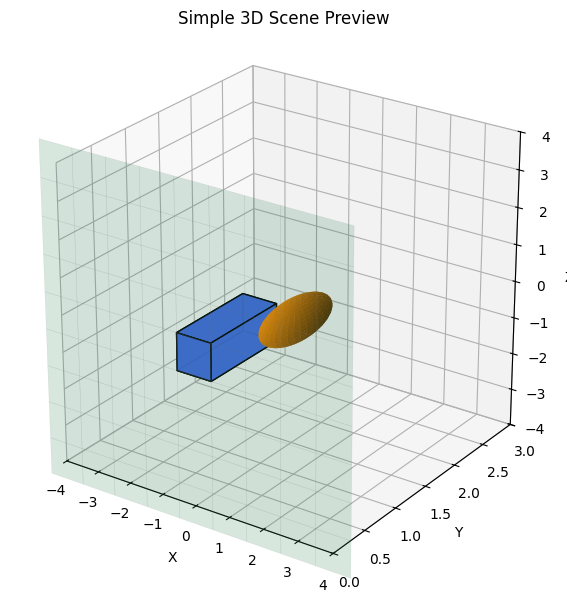

In [2]:
# Experiment 9: Create a Simple Interactive 3D Scene using Unity
# This notebook creates the Unity C# script in the current notebook folder.
# In Google Colab, it downloads the script automatically.

from pathlib import Path
import os

unity_script = r"""
using UnityEngine;

public class Interactive3DScene : MonoBehaviour
{
    public float moveSpeed = 4f;
    public float rotateSpeed = 90f;
    public float scaleSpeed = 1f;

    private GameObject player;

    void Start()
    {
        // Create floor
        GameObject floor = GameObject.CreatePrimitive(PrimitiveType.Plane);
        floor.name = "Floor";
        floor.transform.position = Vector3.zero;
        floor.transform.localScale = new Vector3(3f, 1f, 3f);
        floor.GetComponent<Renderer>().material.color = new Color(0.25f, 0.35f, 0.30f);

        // Create interactive cube
        player = GameObject.CreatePrimitive(PrimitiveType.Cube);
        player.name = "Interactive Cube";
        player.transform.position = new Vector3(0f, 0.5f, 0f);
        player.GetComponent<Renderer>().material.color = new Color(0.15f, 0.55f, 0.95f);

        // Create second object
        GameObject sphere = GameObject.CreatePrimitive(PrimitiveType.Sphere);
        sphere.name = "Sphere";
        sphere.transform.position = new Vector3(2f, 0.5f, 1f);
        sphere.GetComponent<Renderer>().material.color = new Color(1f, 0.55f, 0.15f);

        // Directional light
        GameObject lightObject = new GameObject("Scene Light");
        Light sceneLight = lightObject.AddComponent<Light>();
        sceneLight.type = LightType.Directional;
        sceneLight.intensity = 1.2f;
        lightObject.transform.rotation = Quaternion.Euler(50f, -30f, 0f);

        // Position camera if present
        if (Camera.main != null)
        {
            Camera.main.transform.position = new Vector3(5f, 5f, -8f);
            Camera.main.transform.LookAt(new Vector3(0f, 0.5f, 0f));
        }
    }

    void Update()
    {
        if (player == null) return;

        float horizontal = Input.GetAxis("Horizontal");
        float vertical = Input.GetAxis("Vertical");
        Vector3 movement = new Vector3(horizontal, 0f, vertical);
        player.transform.Translate(movement * moveSpeed * Time.deltaTime, Space.World);

        if (Input.GetKey(KeyCode.Q))
            player.transform.Rotate(Vector3.up, -rotateSpeed * Time.deltaTime, Space.World);
        if (Input.GetKey(KeyCode.E))
            player.transform.Rotate(Vector3.up, rotateSpeed * Time.deltaTime, Space.World);

        if (Input.GetKey(KeyCode.Equals) || Input.GetKey(KeyCode.KeypadPlus))
            player.transform.localScale += Vector3.one * scaleSpeed * Time.deltaTime;

        if (Input.GetKey(KeyCode.Minus) || Input.GetKey(KeyCode.KeypadMinus))
            player.transform.localScale = Vector3.Max(
                Vector3.one * 0.3f,
                player.transform.localScale - Vector3.one * scaleSpeed * Time.deltaTime
            );
    }
}
"""

# Use the current working directory instead of assuming /mnt/data exists.
script_path = Path.cwd() / "Interactive3DScene.cs"
script_path.write_text(unity_script, encoding="utf-8")
print("Unity script saved to:", script_path.resolve())

# Automatically download the C# script in Google Colab.
try:
    from google.colab import files
    files.download(str(script_path))
except ImportError:
    print("Not running in Google Colab. Copy Interactive3DScene.cs into your Unity project's Assets folder.")

print("Controls in Unity: WASD/arrow keys = move, Q/E = rotate, + / - = scale")

# Preview the 3D scene layout in this notebook
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def draw_cube(ax, center, size=1.0, color="royalblue"):
    cx, cy, cz = center
    s = size / 2
    points = np.array([
        [cx-s, cy-s, cz-s], [cx+s, cy-s, cz-s],
        [cx+s, cy+s, cz-s], [cx-s, cy+s, cz-s],
        [cx-s, cy-s, cz+s], [cx+s, cy-s, cz+s],
        [cx+s, cy+s, cz+s], [cx-s, cy+s, cz+s]
    ])
    face_indices = [[0,1,2,3], [4,5,6,7], [0,1,5,4],
                    [2,3,7,6], [1,2,6,5], [0,4,7,3]]
    polygons = [[points[i] for i in face] for face in face_indices]
    ax.add_collection3d(Poly3DCollection(polygons, facecolors=color,
                                         edgecolors="black", alpha=0.95))

def draw_sphere(ax, center, radius=0.5, color="darkorange"):
    u = np.linspace(0, 2*np.pi, 36)
    v = np.linspace(0, np.pi, 20)
    x = center[0] + radius * np.outer(np.cos(u), np.sin(v))
    y = center[1] + radius * np.outer(np.sin(u), np.sin(v))
    z = center[2] + radius * np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(x, y, z, color=color, linewidth=0, shade=True)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

xx, zz = np.meshgrid(np.linspace(-4.5, 4.5, 10), np.linspace(-4.5, 4.5, 10))
yy = np.zeros_like(xx)
ax.plot_surface(xx, yy, zz, color="seagreen", alpha=0.18,
                edgecolor="gray", linewidth=0.3)

draw_cube(ax, (0, 0.5, 0))
draw_sphere(ax, (2, 0.5, 1))
ax.set_xlim(-4, 4)
ax.set_ylim(0, 3)
ax.set_zlim(-4, 4)
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Simple 3D Scene Preview")
ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()
